# Discrete maps: population growth, cobwebs, and sensitive behavior

**Mathematical Methods for Physicists II | Compiled undergraduate exercises**

These exercises iterate $x_{n+1}=f(x_n)$. Although they produce sequences of numbers, the rules are **deterministic**: the same starting value always gives the same sequence. Irregular behavior can arise without random sampling. We will compare several maps, draw cobwebs, and investigate fixed points and sensitivity to initial conditions.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## 1. Logistic population map

Begin with $x_{n+1}=\mu x_n(1-x_n)$, $x_0=0.75$, 30 iterations, and $\mu=2.8,3.3,3.5,3.6,3.8$. Here $x$ is a dimensionless population fraction when $0\leq x\leq1$ and $0\leq\mu\leq4$.


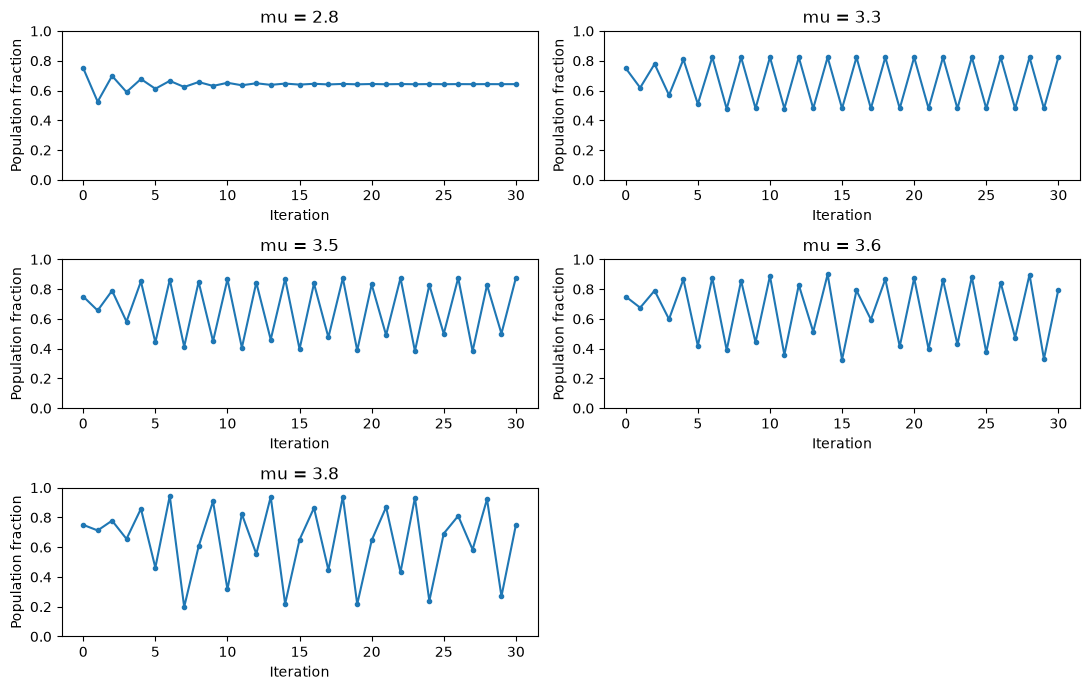

In [2]:
def logistic(mu, initial, steps):
    values = [initial]
    for n in range(steps):
        values.append(mu*values[-1]*(1-values[-1]))
    return values

plt.figure(figsize=(11, 7))
for i, mu in enumerate([2.8, 3.3, 3.5, 3.6, 3.8]):
    values = logistic(mu, 0.75, 30)
    plt.subplot(3, 2, i+1)
    plt.plot(range(len(values)), values, 'o-', markersize=3)
    plt.ylim(0, 1)
    plt.title('mu = ' + str(mu))
    plt.xlabel('Iteration')
    plt.ylabel('Population fraction')
plt.tight_layout()
plt.show()


As $\mu$ rises, the map can settle to one value, alternate between values, or vary irregularly. Thirty iterations give a first impression; longer runs reveal late behavior.



## 2. Cobweb diagrams

A cobweb alternates between the curve $y=f(x)$ and the line $y=x$. The same cobweb function draws both examples: ordinary forward steps for the logistic map and inverse horizontal steps for the $x^2$ diagram.

In [3]:
def cobweb(function, start, steps, inverse=None):
    x = start
    cobweb_x = [x]
    cobweb_y = [0]

    for step in range(steps):
        if inverse is None:
            # Move vertically to y=f(x), then horizontally to y=x.
            y = function(x)
            cobweb_x.append(x)
            cobweb_y.append(y)
            x = y
            cobweb_x.append(x)
            cobweb_y.append(y)
        else:
            # Move vertically to y=x, then horizontally to y=f(x).
            y = x
            cobweb_x.append(x)
            cobweb_y.append(y)
            x = inverse(y)
            cobweb_x.append(x)
            cobweb_y.append(y)
    return cobweb_x, cobweb_y

### The $x^2$ curve

Plot $y=x^2$ together with $y=x$. Start near zero and use $x=\sqrt{y}$ to move **horizontally from a point on the diagonal to the $x^2$ curve**, then move vertically back to the diagonal. This is the construction used here: its staircase climbs toward $(1,1)$. Because the horizontal move uses the inverse function, the staircase represents backward iteration of $x^2$ on $[0,1]$. Forward iteration of $x_{n+1}=x_n^2$ would instead approach zero. The second plot draws $y=\sqrt{x}$ directly and uses ordinary forward cobweb steps; both staircases climb toward one, but their steps are drawn against different curves.

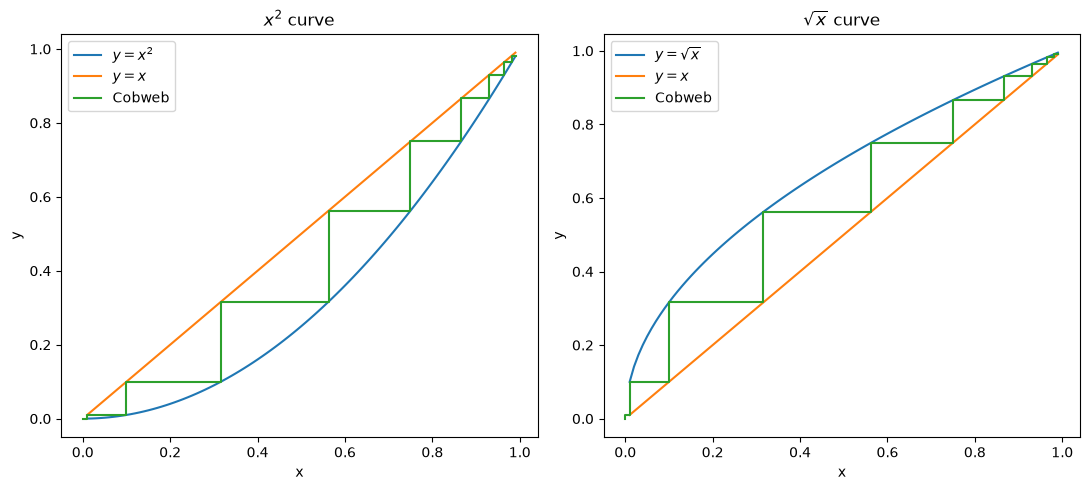

In [4]:
axis = np.arange(0.01, 1.0, 0.01)

# The x^2 curve
x2, y2 = cobweb(lambda x: x**2, 0.0001, 10, inverse=np.sqrt)

# Forward iteration on the inverse curve, sqrt(x)
inv_x, inv_y = cobweb(lambda x: np.sqrt(x), 0.0001, 10)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].plot(axis, axis**2, label=r"$y=x^2$")
axes[0].plot(axis, axis, label=r"$y=x$")
axes[0].plot(x2, y2, label="Cobweb")
axes[0].set_title(r"$x^2$ curve")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()

axes[1].plot(axis, np.sqrt(axis), label=r"$y=\sqrt{x}$")
axes[1].plot(axis, axis, label=r"$y=x$")
axes[1].plot(inv_x, inv_y, label="Cobweb")
axes[1].set_title(r"$\sqrt{x}$ curve")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].legend()

plt.tight_layout()
plt.show()


### The $ \mu x (1 - x)$ curve, in Logistic and Chaotic Regime

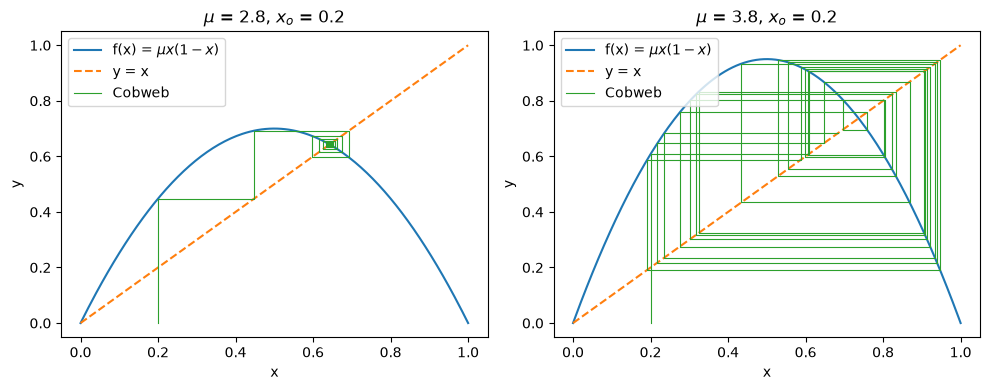

In [5]:
axis = np.linspace(0, 1, 200)
plt.figure(figsize=(10, 4))
for i, mu in enumerate([2.8, 3.8]):
    f = lambda x:mu*x*(1-x)
    xx, yy = cobweb(f, 0.2, 30)
    plt.subplot(1, 2, i+1)
    plt.plot(axis, f(axis), label=r'f(x) = $\mu x (1-x)$')
    plt.plot(axis, axis, '--', label='y = x')
    plt.plot(xx, yy, linewidth=0.8, label='Cobweb')
    plt.title('$ \\mu $ = ' + str(mu) + ', $ x_o $ = 0.2')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


## 3. Four more iterative maps

Use $x_0=0.75$ for each rule:

- **Ecology (Ricker):** $x_{n+1}=x_n\exp[\mu(1-x_n)]$; 30 steps.
- **Gaussian:** $x_{n+1}=\exp(-3x_n^2)+\mu$; 15 steps.
- **Tent-like:** $x_{n+1}=\mu[1-2|x_n-0.5|]$; 10 steps.
- **Quartic:** $x_{n+1}=\mu[1-(2x_n-1)^4]$; 5 steps.

First try $\mu=2.8,3.3,3.5,3.8$ for all four. Notice that the Gaussian map uses an **additive** $\mu$. The large parameter values are outside the interval-preserving range of the tent and quartic maps, so their trajectories may escape $[0,1]$ or grow very rapidly. This is a parameter-domain issue, not evidence of bounded chaos. Stop plotting once $|x|>100$.


Tent μ = 2.8 stopped after 5 steps: |x| > 100
Tent μ = 3.3 stopped after 4 steps: |x| > 100
Tent μ = 3.5 stopped after 4 steps: |x| > 100
Tent μ = 3.8 stopped after 4 steps: |x| > 100
Quartic μ = 2.8 stopped after 2 steps: |x| > 100
Quartic μ = 3.3 stopped after 2 steps: |x| > 100
Quartic μ = 3.5 stopped after 2 steps: |x| > 100
Quartic μ = 3.8 stopped after 2 steps: |x| > 100


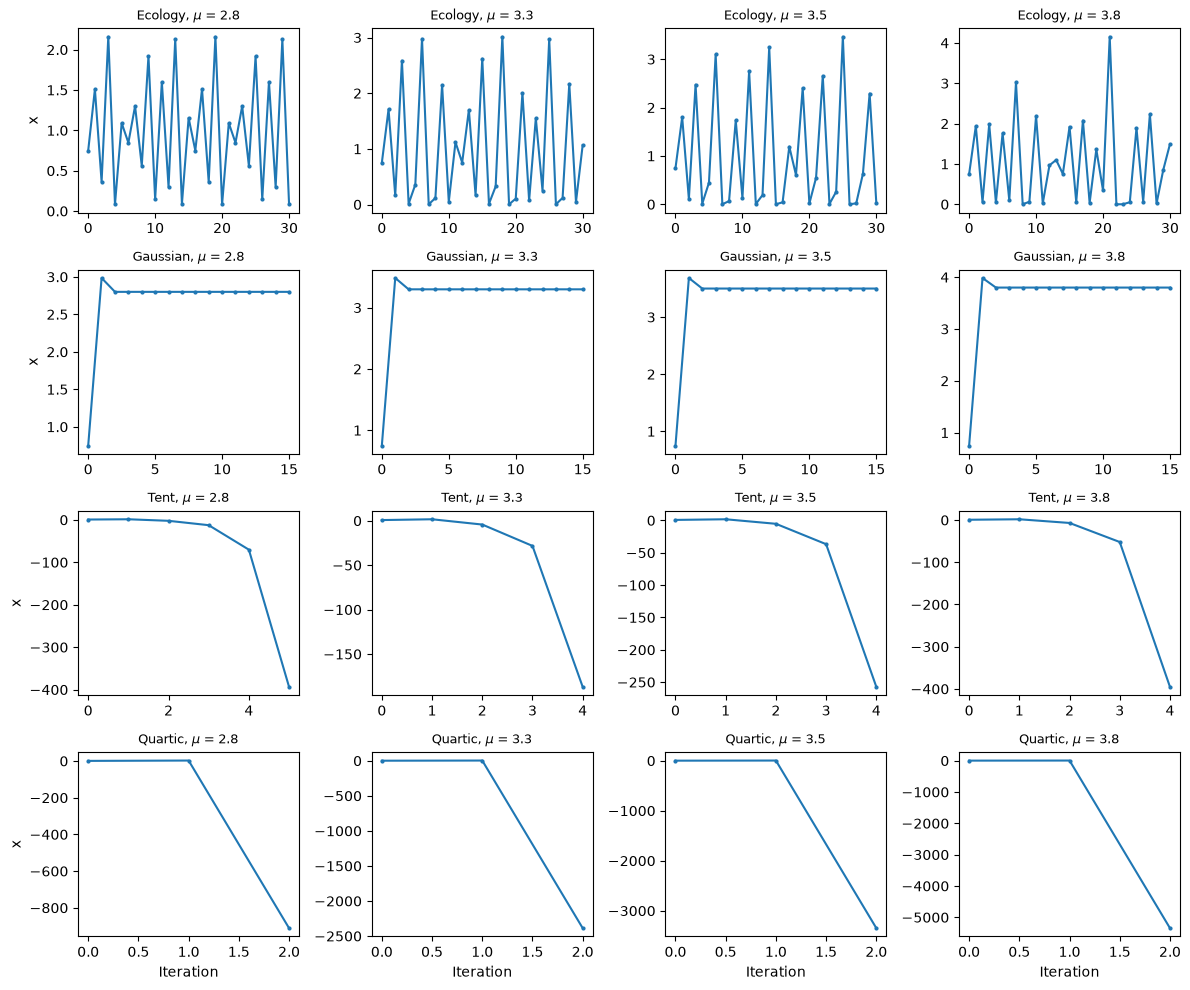

In [6]:
def mapping(name, mu, initial, steps):
    values = [initial]
    for n in range(steps):
        x = values[-1]
        if name == 'Ecology':
            new_x = x*math.exp(mu*(1-x))
        elif name == 'Gaussian':
            new_x = math.exp(-3*x*x) + mu
        elif name == 'Tent':
            new_x = mu*(1-2*abs(x-0.5))
        elif name == 'Quartic':
            new_x = mu*(1-(2*x-1)**4)
        else:
            raise ValueError('Unknown map')
        values.append(new_x)
        if not np.isfinite(new_x) or abs(new_x)>100:
            break
    return values

names_and_steps = [('Ecology',30), ('Gaussian',15), ('Tent',10), ('Quartic',5)]
mu_choices = [2.8, 3.3, 3.5, 3.8]
plt.figure(figsize=(12, 10))
for row, (name, steps) in enumerate(names_and_steps):
    for col, mu in enumerate(mu_choices):
        values = mapping(name, mu, 0.75, steps)
        plt.subplot(4, 4, 4*row+col+1)
        plt.plot(range(len(values)), values, 'o-', markersize=2)
        plt.title(name + ', $\\mu$ = ' + str(mu), fontsize=9)
        if row==3:plt.xlabel('Iteration')
        if col==0:plt.ylabel('x')
        if len(values)<steps+1:
            print(name, 'μ =',mu, 'stopped after',len(values)-1,'steps: |x| > 100')
plt.tight_layout()
plt.show()


For the tent-like and quartic rules, $\mu\leq1$ keeps $x$ in $[0,1]$ when it starts there. Compare several values in that range to the earlier large-parameter runs. The two choices answer different questions.


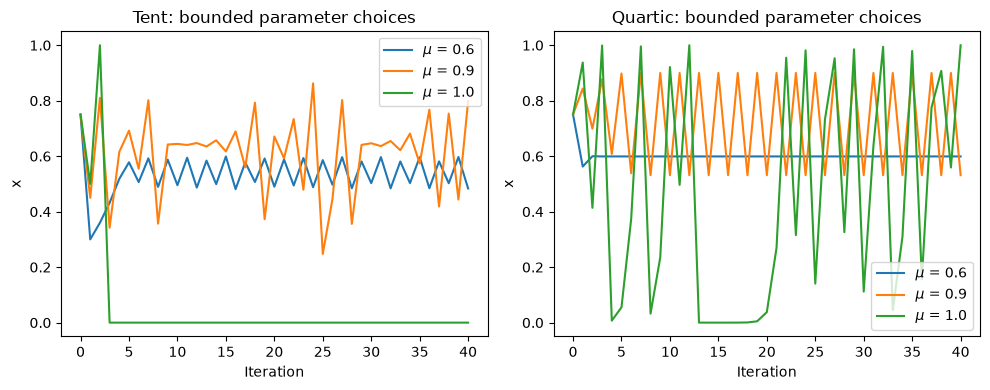

In [7]:
plt.figure(figsize=(10, 4))
for i, name in enumerate(['Tent','Quartic']):
    plt.subplot(1, 2, i+1)
    for mu in [0.6, 0.9, 1.0]:
        values = mapping(name, mu, 0.75, 40)
        plt.plot(range(len(values)), values, label='$\\mu$ = ' + str(mu))
    plt.title(name + ': bounded parameter choices')
    plt.xlabel('Iteration')
    plt.ylabel('x')
    plt.legend()
plt.tight_layout()
plt.show()


## 4. Fixed points and sensitive starting conditions

For the logistic map, a nonzero fixed point is $x_*=1-1/\mu$. A small disturbance $\delta x$ is multiplied approximately by $|f'(x_*)|=|2-\mu|$ each step, so this fixed point is locally attracting when $1<\mu<3$.

Next, compare two logistic trajectories that start just $10^{-6}$ apart at $\mu=2.8$ and $3.8$. A growing separation at $3.8$ illustrates sensitivity to initial conditions. It does not prove a general statement about every parameter or initial state.


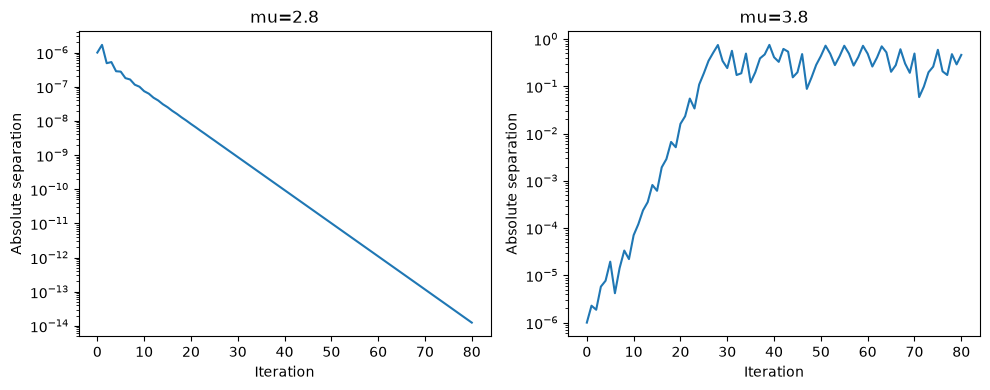

At mu=2.8: fixed point 0.6429 and slope magnitude 0.8


In [8]:
plt.figure(figsize=(10, 4))
for i, mu in enumerate([2.8, 3.8]):
    first = logistic(mu, 0.2, 80)
    second = logistic(mu, 0.200001, 80)
    difference = [abs(first[j]-second[j]) for j in range(len(first))]
    plt.subplot(1, 2, i+1)
    plt.semilogy(range(len(difference)), difference)
    plt.xlabel('Iteration')
    plt.ylabel('Absolute separation')
    plt.title('mu=' + str(mu))
plt.tight_layout()
plt.show()
print('At mu=2.8: fixed point',round(1-1/2.8,4),'and slope magnitude',round(abs(2-2.8),2))


## 5. Bifurcation diagram

Keep the late values of many logistic runs at different $\mu$. Their vertical spread changes from a single line to branches and then more complex structure. Dense regions do not by themselves quantify probabilities.


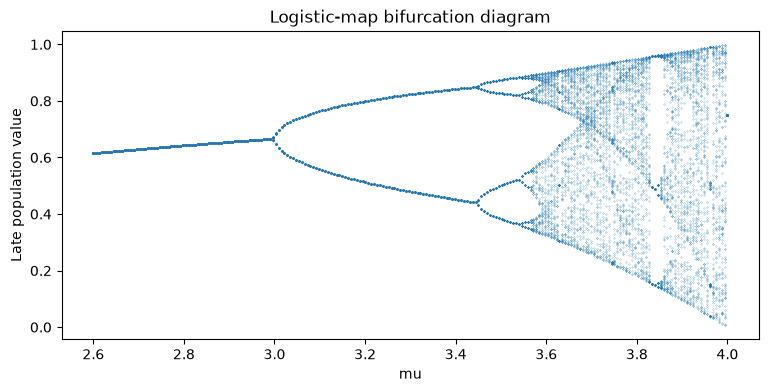

In [9]:
parameters = np.linspace(2.6, 4.0, 220)
mu_points = []
x_points = []
for mu in parameters:
    x = 0.75
    for step in range(450):
        x = mu*x*(1-x)
        if step>=350:
            mu_points.append(mu)
            x_points.append(x)
plt.figure(figsize=(9, 4))
plt.plot(mu_points, x_points, '.', markersize=0.35)
plt.xlabel('mu')
plt.ylabel('Late population value')
plt.title('Logistic-map bifurcation diagram')
plt.show()


## Summary

Iterative maps can show stable fixed points, alternating patterns, and sensitive behavior. The cobwebs visualize repeated application of a rule. Always check a map's parameter range before interpreting a rapidly escaping trajectory as chaos.
